# Tema 1 · Teoría de la utilidad y decisiones bajo riesgo — Ejercicio práctico (Python)
**Luiz Luzuriaga** · Máster en Ciencias Actuariales y Financieras · Matemática Actuarial de la Estabilidad y Solvencia

Contenido: (A) curvas CRRA/CARA, (B) Caso 2 por perfil de aversión, (C) umbrales de aceptación,
(D) Caso 1: zona de acuerdo cedente–reasegurador, (E) Arrow–Pratt frente a la prima exacta.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq

def u_crra(w, gamma):
    w = np.asarray(w, float)
    return np.log(w) if gamma == 1 else w**(1 - gamma) / (1 - gamma)

def u_cara(w, alpha):
    return -np.exp(-alpha * np.asarray(w, float)) / alpha

perfiles = pd.DataFrame({
    "perfil": ["Agresivo CRRA", "Moderado CRRA", "Conservador CRRA",
               "Agresivo CARA", "Moderado CARA", "Conservador CARA"],
    "tipo":   ["CRRA"] * 3 + ["CARA"] * 3,
    "param":  [0.5, 2, 5, 1e-4, 3e-4, 6e-4]})

## (A) Curvas de utilidad normalizadas
Se normaliza cada curva a [0, 1] para comparar solo la **curvatura** (la utilidad es única salvo transformación afín positiva).

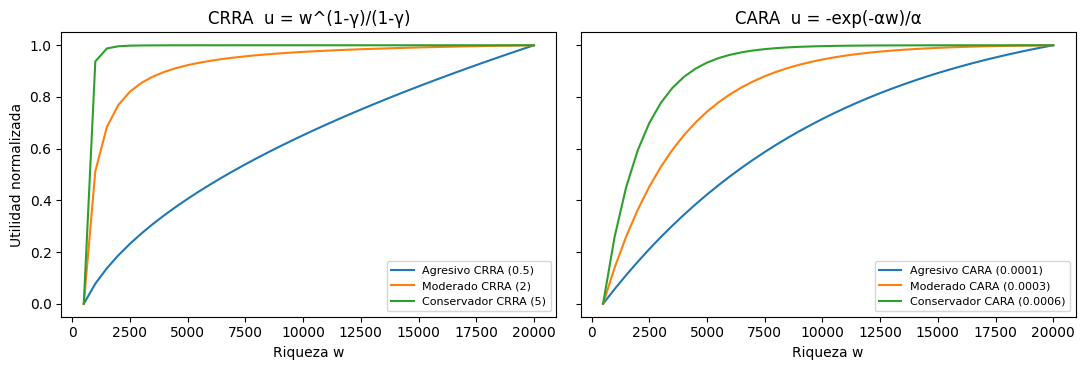

In [2]:
w_grid = np.arange(500, 20001, 500)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for _, f in perfiles.iterrows():
    u = u_crra(w_grid, f.param) if f.tipo == "CRRA" else u_cara(w_grid, f.param)
    un = (u - u.min()) / (u.max() - u.min())
    ax[0 if f.tipo == "CRRA" else 1].plot(w_grid, un, label=f"{f.perfil} ({f.param:g})")
for a, t in zip(ax, ["CRRA  u = w^(1-γ)/(1-γ)", "CARA  u = -exp(-αw)/α"]):
    a.set_title(t); a.set_xlabel("Riqueza w"); a.legend(fontsize=8)
ax[0].set_ylabel("Utilidad normalizada"); plt.tight_layout(); plt.show()

## (B) Caso 2 — mesa de tesorería: equivalente cierto y prima de riesgo
Posición: $+2.000$ con $p=0{,}5$ y $-1.500$ con $p=0{,}5$, riqueza $w=10.000$ (miles €), $E[W]=10.250$.
Se resuelve $u(CE)=E[u(w+X)]$ de forma cerrada en cada familia:
$CE_{CRRA}=\big(E[W^{1-\gamma}]\big)^{1/(1-\gamma)}$ ($\gamma\neq1$), $CE_{\log}=\exp E[\ln W]$ y $CE_{CARA}=-\tfrac1\alpha\ln E[e^{-\alpha W}]$.

In [3]:
w, up, dn, p = 10_000.0, 2_000.0, -1_500.0, 0.5
W = np.array([w + up, w + dn]); pr = np.array([p, 1 - p]); EW = pr @ W

def ce_posicion(tipo, k):
    if tipo == "CRRA":
        return float(np.exp(pr @ np.log(W))) if k == 1 else float((pr @ W**(1 - k))**(1 / (1 - k)))
    return float(-np.log(pr @ np.exp(-k * W)) / k)

res = perfiles.copy()
res["CE"] = [ce_posicion(t, k) for t, k in zip(res.tipo, res.param)]
res["E[W]"] = EW
res["prima_pi"] = EW - res.CE
res["acepta"] = res.CE > w
res.round(2)

,perfil,tipo,param,CE,E[W],prima_pi,acepta
0,Agresivo CRRA,CRRA,0.5,10174.75,10250.0,75.25,True
1,Moderado CRRA,CRRA,2.0,9951.22,10250.0,298.78,False
2,Conservador CRRA,CRRA,5.0,9556.48,10250.0,693.52,False
3,Agresivo CARA,CARA,0.0,10097.65,10250.0,152.35,True
4,Moderado CARA,CARA,0.0,9810.30,10250.0,439.70,False
5,Conservador CARA,CARA,0.0,9462.71,10250.0,787.29,False


**Lectura.** La prima de riesgo crece monótonamente con la aversión. Aceptan solo los perfiles agresivos (γ=0,5 y α=10⁻⁴);
el resto rechaza una posición de valor esperado **positivo** (+250) porque $\pi>250$ o, equivalentemente, $CE<w$.

## (C) Umbrales críticos de aversión
Máxima aversión que aún acepta la posición: raíz de $CE(\theta)=w$. Es el tipo de output que usaría un comité de riesgos para fijar límites por mesa.

γ* = 1.6676   α* = 0.000166
Caso logarítmico (γ=1): CE = 10099.5  π = 150.5


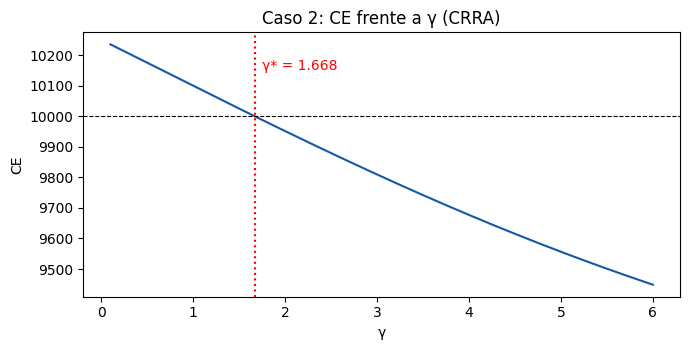

In [4]:
g_star = brentq(lambda g: ce_posicion("CRRA", g) - w, 1.01, 6, xtol=1e-12)
a_star = brentq(lambda a: ce_posicion("CARA", a) - w, 1e-6, 1e-3, xtol=1e-14)
print(f"γ* = {g_star:.4f}   α* = {a_star:.6f}")
print(f"Caso logarítmico (γ=1): CE = {ce_posicion('CRRA', 1):.1f}  π = {EW - ce_posicion('CRRA', 1):.1f}")

gs = np.linspace(0.1, 6, 300)
plt.figure(figsize=(7, 3.6))
plt.plot(gs, [ce_posicion("CRRA", g) for g in gs], color="#1559a6")
plt.axhline(w, ls="--", c="k", lw=.8); plt.axvline(g_star, ls=":", c="r")
plt.text(g_star + .08, 10150, f"γ* = {g_star:.3f}", color="r")
plt.xlabel("γ"); plt.ylabel("CE"); plt.title("Caso 2: CE frente a γ (CRRA)"); plt.tight_layout(); plt.show()

## (D) Caso 1 — zona de acuerdo en un contrato exponencial
$X=\theta Y$, $Y\sim\Gamma(n,1)$ con $n=2$, $\theta=500$ ⇒ $M_X(t)=(1-\theta t)^{-n}$ para $t<1/\theta=0{,}002$. Prima exponencial: $P(\alpha)=\ln M_X(\alpha)/\alpha$.

P+ = 1188.92   P- = 1083.46   anchura = 105.46
Recargo cedente = 18.9%   recargo reasegurador = 8.3%
Límite α_R→0: P- → 1000.00  (anchura máxima 188.92)


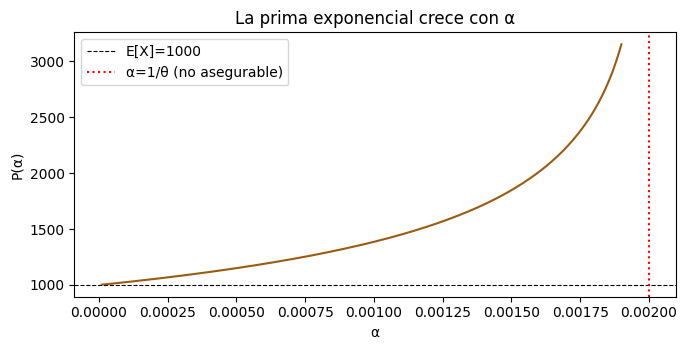

In [5]:
n, theta = 2, 500.0
def prima_exp(alpha):
    assert alpha < 1 / theta, "M_X(α) no existe: riesgo no asegurable con esa aversión"
    return -n * np.log(1 - theta * alpha) / alpha

P_mas, P_menos = prima_exp(6e-4), prima_exp(3e-4)
print(f"P+ = {P_mas:.2f}   P- = {P_menos:.2f}   anchura = {P_mas - P_menos:.2f}")
print(f"Recargo cedente = {100*(P_mas/1000-1):.1f}%   recargo reasegurador = {100*(P_menos/1000-1):.1f}%")
print(f"Límite α_R→0: P- → {prima_exp(1e-9):.2f}  (anchura máxima {P_mas - prima_exp(1e-9):.2f})")

al = np.linspace(1e-5, 1.9e-3, 300)
plt.figure(figsize=(7, 3.6))
plt.plot(al, [prima_exp(a) for a in al], color="#9a5b12")
plt.axhline(1000, ls="--", c="k", lw=.8, label="E[X]=1000")
plt.axvline(1 / theta, ls=":", c="r", label="α=1/θ (no asegurable)")
plt.xlabel("α"); plt.ylabel("P(α)"); plt.legend(); plt.title("La prima exponencial crece con α"); plt.tight_layout(); plt.show()

## (E) Arrow–Pratt frente a la prima exacta
$\pi\approx\tfrac12\,r(\bar w)\,\sigma^2$ con $\bar w=E[W]$, $r=\gamma/\bar w$ (CRRA) o $r=\alpha$ (CARA), $\sigma^2=\mathrm{Var}[X]=\big(p(1-p)\big)(2000+1500)^2$.

In [6]:
var_x = p * (1 - p) * (up - dn)**2
r_loc = np.where(res.tipo == "CRRA", res.param / EW, res.param)
res["pi_AP"] = 0.5 * r_loc * var_x
res["error_%"] = 100 * (res.pi_AP / res.prima_pi - 1)
res[["perfil", "prima_pi", "pi_AP", "error_%"]].round(2)

,perfil,prima_pi,pi_AP,error_%
0,Agresivo CRRA,75.25,74.70,-0.73
1,Moderado CRRA,298.78,298.78,0.00
2,Conservador CRRA,693.52,746.95,7.70
3,Agresivo CARA,152.35,153.12,0.51
4,Moderado CARA,439.70,459.37,4.47
5,Conservador CARA,787.29,918.75,16.70


**Lectura.** La aproximación local falla cuanto mayor es la aversión (error ≈ +17 % para CARA conservador): el riesgo ya no es «pequeño»
frente a la riqueza y pesan los momentos de orden superior. Para riesgos grandes hay que usar la prima exacta.